# 04 - Age and Students' success
In this notebook, we will be looking at students' demographic infomation beyond location. Specifically, we will analyze `isAdult` and `isPartner` columns, and compare success (finalgrades, withdraw, ...) between students with different features on these columns.

In [200]:
import sys

sys.path.append("..")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from src.mongo_connect import get_db
from src.location import add_location_columns

# white background for every figure, also when the IDE uses a dark theme
plt.style.use("default")
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
})

db = get_db()
print(db.name)

nexus


## 1. Preparing the dataset
### 1.1 Group students in three groups

We hope to grope students in three groups to compare their performance.

1. Is Partner & Is Not Adult (all partner students are high school students).
2. Non Partner & Is Adult
3. Non Partner & Is Not Adult

Load students from the past 5 academic years (`startDate >= 2021-08-01`), the same window as notebook 02.

In [201]:
Start_DATE = "2021-08-01"  # same 5-academic-year window as notebook 02

df_full = pd.DataFrame(list(db.students.find({
    "startDate": {"$gte": pd.Timestamp(Start_DATE)}
})))

print(df_full.shape)

(6824, 54)


Before grouping, check the assumption that **every partner student is not an adult** (partner students are high schoolers). If the `isPartner=True, isAdult=True` cell isn't 0, we have to decide how to handle those students.

In [202]:
print(df_full[["isPartner", "isAdult"]].dtypes)
print("\nmissing:")
print(df_full[["isPartner", "isAdult"]].isna().sum())

pd.crosstab(df_full["isPartner"], df_full["isAdult"], dropna=False, margins=True)

isPartner    bool
isAdult      bool
dtype: object

missing:
isPartner    0
isAdult      0
dtype: int64


isAdult,False,True,All
isPartner,,,
False,361,4216,4577
True,2247,0,2247
All,2608,4216,6824


We proved that are partner students are not adult. So the three groups proposed above work.

Create the `group` column:
1. **Partner (HS)**: `isPartner == True`
2. **Non-partner Adult**: `isPartner == False` & `isAdult == True`
3. **Non-partner Not Adult**: `isPartner == False` & `isAdult == False`

In [203]:
GROUP_ORDER = ["Partner Not Adult", "Non-partner Adult", "Non-partner Not Adult"]

conditions = [
    df_full["isPartner"] ,    # group 1
    ~df_full["isPartner"] & df_full["isAdult"],    # group 2
    ~df_full["isPartner"] & ~df_full["isAdult"],   # group 3
]
df_full["group"] = np.select(conditions, GROUP_ORDER, default="Other")

group_counts = df_full["group"].value_counts().reindex(GROUP_ORDER + ["Other"], fill_value=0)
print(group_counts)
print("\nshare (%):")
print((group_counts / len(df_full) * 100).round(1))

group
Partner Not Adult        2247
Non-partner Adult        4216
Non-partner Not Adult     361
Other                       0
Name: count, dtype: int64

share (%):
group
Partner Not Adult        32.9
Non-partner Adult        61.8
Non-partner Not Adult     5.3
Other                     0.0
Name: count, dtype: float64


In [204]:
df_full.head()

,_id,name,mathable,mentor,location,netId,email,otherEmails,defunctEmails,phones,...,finalGrade,finalExam,hasCompletedQualtricsSurvey,courseOrientation,inactiveEmail,proctorUAccessCode,personal,accommodation,prairieLearn,group
0,60d1e14894fed001b0fc8a56,"{'first': 'Sharon', 'last': 'Wang'}",{'loginToken': ''},"{'name': {'first': 'Tayyab', 'last': 'Nawaz'},...","{'geocode': {'type': 'Point', 'coordinates': [...",sjwang3,sjwang3@illinois.edu,[wang.sharon93@gmail.com],[],[978-569-8189],...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Non-partner Adult
1,60d332cdcba1cd0254f595cb,"{'first': 'Kimaya', 'last': 'Urdhwareshe'}",{'loginToken': ''},"{'comments': [60e7314e99934403d80c69f8, 60d3d0...","{'geocode': {'type': 'Point', 'coordinates': [...",kimayau2,kimayau2@illinois.edu,[kimaya23@gmail.com],[],[669-234-6136],...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Non-partner Adult
2,60d5d5cb70f38d00d2e90fca,"{'first': 'Jian', 'last': 'Deng'}",{'loginToken': 'eyJhbGciOiJIUzI1NiIsInR5cCI6Ik...,"{'comments': [60e4d4bb99934403d80c68e4, 60dc74...","{'formatted': '1740 E 17th St, Brooklyn, NY 11...",jiand2,jiand2@illinois.edu,[jiandeng2519@gmail.com],[],[150-059-2007],...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Non-partner Adult
3,60e304c98e77b0046d3c8a83,"{'first': 'Xinyi', 'last': 'Jiang'}",{'loginToken': 'eyJhbGciOiJIUzI1NiIsInR5cCI6Ik...,"{'comments': [], 'name': {'first': 'Michael', ...","{'formatted': '22, Jalan Anggerik Vanda 31/168...",xinyij5,jxinyi18@gmail.com,[xinyij5@illinois.edu],[],[162-078-908],...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Non-partner Adult
4,60e5a7c9220e540547d752c2,"{'first': 'Merlin', 'last': 'Want'}",{'loginToken': ''},"{'name': {'first': 'Jason', 'last': 'Elliot'},...","{'geocode': {'type': 'Point', 'coordinates': [...",mwant2,merlinwant@gmail.com,"[mwant2@illinois.edu, thedweebconvention@gmail...",[],[202-258-1996],...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Non-partner Adult


### 1.2 Match `finalGrade` and `Withdraw` values to the dataset

`students.finalGrade` is not a grade. It is a pointer (ObjectId) into the `finalgrades` collection, and it is NaN when the student never received a final grade (mostly withdrawn / still active students).

Same method as notebook 02 section 3: pull the matching `finalgrades` documents by `_id`, then left-merge their `grade` back as `finalGradeLetter`, and map it to `gpa`. The original `finalGrade` pointer column is kept so we can always trace a grade back to its source document.

In [205]:
print("students with a finalGrade pointer:", df_full["finalGrade"].notna().sum(), "of", len(df_full))

finalgrade_ids = df_full["finalGrade"].dropna().tolist()

df_fg = pd.DataFrame(list(db.finalgrades.find({"_id": {"$in": finalgrade_ids}})))[["_id", "grade"]]
df_fg = df_fg.rename(columns={"_id": "finalGrade", "grade": "finalGradeLetter"})
print("matched finalgrades documents:", len(df_fg))

df_full = df_full.merge(df_fg, on="finalGrade", how="left")

GRADE_TO_GPA = {
    "A+": 4.0, "A": 4.0, "A-": 3.7,
    "B+": 3.3, "B": 3.0, "B-": 2.7,
    "C+": 2.3, "C": 2.0, "C-": 1.7,
    "D+": 1.3, "D": 1.0, "D-": 0.7,
    "F": 0.0,
    # "W" (withdraw) and "Abs" -> NaN GPA
}
df_full["gpa"] = df_full["finalGradeLetter"].map(GRADE_TO_GPA)

print("rows after merge:", len(df_full))  # should still be 6824 -- no duplicated students
df_full["finalGradeLetter"].value_counts(dropna=False)

students with a finalGrade pointer: 4400 of 6824
matched finalgrades documents: 4400
rows after merge: 6824


finalGradeLetter
NaN    2424
A      1265
A+      955
A-      631
F       363
B       356
B+      333
B-      155
C       120
C+       94
C-       55
D        34
D+       22
D-       16
W         1
Name: count, dtype: int64

Withdraw info comes from `students.status`, which has 4 values: `Completed`, `Withdrawn`, `Withdrawing`, `Active`.

New column `withdrawn`:
- `True` -- `Withdrawn` or `Withdrawing` (in the middle of dropping, will end as withdrawn)
- `False` -- `Completed`
- `<NA>` -- `Active`: still taking the course, outcome unknown yet, so they shouldn't count as either

In [206]:
print(df_full["status"].value_counts(dropna=False))

WITHDRAW_STATUSES = {"Withdrawn", "Withdrawing"}

# nullable boolean: True / False, and <NA> for students still Active
df_full["withdrawn"] = df_full["status"].isin(WITHDRAW_STATUSES).astype("boolean")
df_full.loc[df_full["status"] == "Active", "withdrawn"] = pd.NA

print()
print(df_full["withdrawn"].value_counts(dropna=False))

status
Completed      4398
Withdrawn      1740
Active          574
Withdrawing     112
Name: count, dtype: int64

withdrawn
False    4398
True     1852
<NA>      574
Name: count, dtype: Int64


In [207]:
# check whether students without a grade line up with Withdrawn / Active
pd.crosstab(df_full["status"], df_full["finalGradeLetter"].notna().rename("has_grade"), margins=True)

has_grade,False,True,All
status,,,
Active,574,0,574
Completed,1,4397,4398
Withdrawing,112,0,112
Withdrawn,1737,3,1740
All,2424,4400,6824


### 1.3 Compare three groups' finalgrade

Time axis: `term` is an **academic-year** code (found in notebook 03): `1` + end year + `7`, e.g. `120227` = AY 2021-22.
- AY 2020-21 is **dropped from the whole notebook**: only 70 students fall in the `startDate` window for that year, too few to support any comparison.
- AY 2026-27 has only just started, so it is left out of the trend.

GPA only exists for students who received a letter grade, so withdrawn and active students drop out here; they are covered by the withdraw rate in 1.4. Each point is the average GPA of all graded students in that group and year. Check the `n` table before reading a point: group-years with fewer than `MIN_N` students (e.g. Non-partner Not Adult in 2022-23) are not reliable.

In [208]:
def term_to_academic_year(term):  # same as notebook 03
    end_year = int(str(int(term))[1:5])
    return f"{end_year - 1}-{str(end_year)[2:]}"

df_full["academic_year"] = df_full["term"].map(term_to_academic_year)

# AY 2020-21: only 70 students got in through the startDate window (late starts of the
# previous year), too few to support any comparison -> drop from all of notebook 04
EXCLUDED_YEARS = ["2020-21"]
print("dropped rows:", df_full["academic_year"].isin(EXCLUDED_YEARS).sum())
df_full = df_full[~df_full["academic_year"].isin(EXCLUDED_YEARS)].copy()

PARTIAL_YEARS = ["2026-27"]  # just started -- most students still Active, few grades yet

pd.crosstab(df_full["academic_year"], df_full["group"], margins=True)[GROUP_ORDER + ["All"]]

dropped rows: 70


group,Partner Not Adult,Non-partner Adult,Non-partner Not Adult,All
academic_year,,,,
2021-22,394,962,74,1430
2022-23,396,562,12,970
2023-24,436,818,41,1295
2024-25,512,688,57,1257
2025-26,509,976,113,1598
2026-27,0,150,54,204
All,2247,4156,351,6754


In [209]:
MIN_N = 15  # minimum graded students to trust a group-year average (same threshold as notebook 02)

df_gpa = df_full[df_full["gpa"].notna()]
full_years = sorted(y for y in df_gpa["academic_year"].unique() if y not in PARTIAL_YEARS)

gpa_by_year = (
    df_gpa[df_gpa["academic_year"].isin(full_years)]
    .groupby(["academic_year", "group"])["gpa"]
    .agg(n="count", avg_gpa="mean", std_gpa="std")
)
avg_gpa = gpa_by_year["avg_gpa"].unstack("group")[GROUP_ORDER]
n_gpa = gpa_by_year["n"].unstack("group")[GROUP_ORDER].fillna(0).astype(int)
std_gpa = gpa_by_year["std_gpa"].unstack("group")[GROUP_ORDER]

print("graded students per group-year (n):")
print(n_gpa)
print("\naverage GPA:")
avg_gpa.round(3)

graded students per group-year (n):
group          Partner Not Adult  Non-partner Adult  Non-partner Not Adult
academic_year                                                             
2021-22                      378                526                     46
2022-23                      373                297                     12
2023-24                      421                431                     34
2024-25                      492                412                     48
2025-26                      490                349                     57

average GPA:


group,Partner Not Adult,Non-partner Adult,Non-partner Not Adult
academic_year,,,
2021-22,3.640,2.886,3.683
2022-23,3.586,2.781,3.867
2023-24,3.713,2.606,3.424
2024-25,3.673,2.956,3.165
2025-26,3.552,3.204,3.553


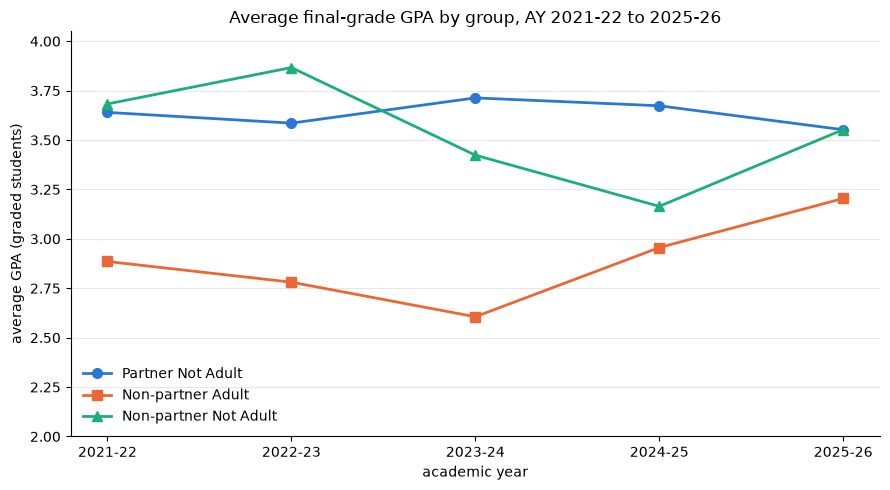

In [210]:
GROUP_COLORS = {  # fixed per group, reused in every chart of this notebook
    "Partner Not Adult": "#2a78d6",
    "Non-partner Adult": "#eb6834",
    "Non-partner Not Adult": "#1baf7a",
}
GROUP_MARKERS = {"Partner Not Adult": "o", "Non-partner Adult": "s", "Non-partner Not Adult": "^"}

fig, ax = plt.subplots(figsize=(9, 5), facecolor="white")
ax.set_facecolor("white")
x = np.arange(len(full_years))

for group in GROUP_ORDER:
    ax.plot(x, avg_gpa[group].values, color=GROUP_COLORS[group], linewidth=2, label=group,
            marker=GROUP_MARKERS[group], markersize=7)

ax.set_xticks(x, full_years)
ax.set_ylim(2.0, 4.05)  # GPA averages all sit between 2.5 and 4 -- a 0 baseline would flatten the gaps
ax.set_xlabel("academic year")
ax.set_ylabel("average GPA (graded students)")
ax.set_title(f"Average final-grade GPA by group, AY {full_years[0]} to {full_years[-1]}")
ax.legend(frameon=False, loc="lower left")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [211]:
# pooled over all full years: one number per group
gpa_overall = (
    df_gpa[df_gpa["academic_year"].isin(full_years)]
    .groupby("group")["gpa"]
    .agg(n="count", avg_gpa="mean", median_gpa="median", std_gpa="std")
    .reindex(GROUP_ORDER)
    .round(3)
)
gpa_overall

,n,avg_gpa,median_gpa,std_gpa
group,,,,
Partner Not Adult,2154,3.633,4.0,0.586
Non-partner Adult,2015,2.880,3.7,1.483
Non-partner Not Adult,197,3.485,4.0,1.086


### 1.4 Compare three groups' withdraw rate

withdraw rate calculated by withdrawn==True / withdrawn!=<NA>

In [212]:
# students with a known outcome only: Active (withdrawn = <NA>) are left out of both numerator and denominator
df_wd = df_full[df_full["withdrawn"].notna() & df_full["academic_year"].isin(full_years)].copy()
df_wd["withdrawn"] = df_wd["withdrawn"].astype(bool)

wd_by_year = (
    df_wd.groupby(["academic_year", "group"])["withdrawn"]
    .agg(n="count", n_withdrawn="sum", withdraw_rate="mean")
)
wd_rate = (wd_by_year["withdraw_rate"].unstack("group")[GROUP_ORDER] * 100)  # in %
n_wd = wd_by_year["n"].unstack("group")[GROUP_ORDER].fillna(0).astype(int)

print("students with a known outcome per group-year (n):")
print(n_wd)
print("\nwithdraw rate (%):")
wd_rate.round(1)

students with a known outcome per group-year (n):
group          Partner Not Adult  Non-partner Adult  Non-partner Not Adult
academic_year                                                             
2021-22                      394                962                     74
2022-23                      396                562                     12
2023-24                      436                818                     41
2024-25                      512                688                     57
2025-26                      509                647                     69

withdraw rate (%):


group,Partner Not Adult,Non-partner Adult,Non-partner Not Adult
academic_year,,,
2021-22,4.1,45.3,37.8
2022-23,5.8,47.2,0.0
2023-24,3.4,47.4,17.1
2024-25,3.9,40.1,15.8
2025-26,3.7,45.9,18.8


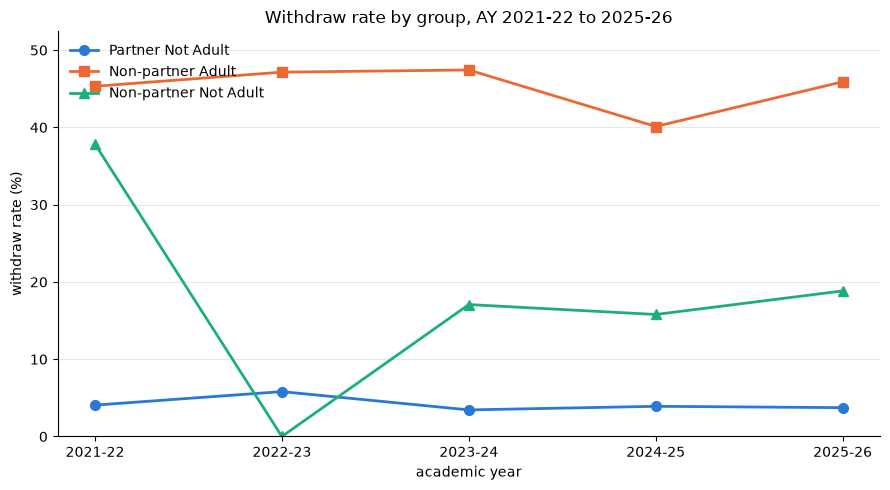

In [213]:
fig, ax = plt.subplots(figsize=(9, 5), facecolor="white")
ax.set_facecolor("white")
x = np.arange(len(full_years))

for group in GROUP_ORDER:  # same colors / markers as the GPA chart in 1.3
    ax.plot(x, wd_rate[group].values, color=GROUP_COLORS[group], linewidth=2, label=group,
            marker=GROUP_MARKERS[group], markersize=7)

ax.set_xticks(x, full_years)
ax.set_ylim(0, max(50, wd_rate.max().max() + 5))  # rates: keep the 0 baseline
ax.set_xlabel("academic year")
ax.set_ylabel("withdraw rate (%)")
ax.set_title(f"Withdraw rate by group, AY {full_years[0]} to {full_years[-1]}")
ax.legend(frameon=False, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [214]:
# pooled over all full years: one number per group
wd_overall = (
    df_wd.groupby("group")["withdrawn"]
    .agg(n="count", n_withdrawn="sum", withdraw_rate="mean")
    .reindex(GROUP_ORDER)
)
wd_overall["withdraw_rate_%"] = (wd_overall.pop("withdraw_rate") * 100).round(1)
wd_overall

,n,n_withdrawn,withdraw_rate_%
group,,,
Partner Not Adult,2247,93,4.1
Non-partner Adult,3677,1662,45.2
Non-partner Not Adult,253,57,22.5


## 2. Course as a factor
**Partner Not Adult** does best (avg GPA 3.63, withdraw 4.1%), **Non-partner Not Adult** is in the middle (3.49, 22.5%), and **Non-partner Adult** does worst (2.88, 45.2%).

Is that because the groups take **different courses**? (Guess: adult students may take higher-level, harder courses.)

In [215]:
df_full["course"] = df_full["course"].astype(int)
df_full["course_level"] = (df_full["course"] // 100 * 100).astype(str) + "-level"  # 241 -> "200-level"

df_gpa = df_full[df_full["gpa"].notna() & df_full["academic_year"].isin(full_years)]
df_wd = df_full[df_full["withdrawn"].notna() & df_full["academic_year"].isin(full_years)].copy()
df_wd["withdrawn"] = df_wd["withdrawn"].astype(bool)

print("distinct courses:", df_full["course"].nunique())
df_full["course_level"].value_counts()

distinct courses: 29


course_level
200-level    3461
400-level    3013
100-level     232
300-level      48
Name: count, dtype: int64

### 2.1 Course mix of each group

First check whether the three groups actually take different courses. Shown as the % of each group's enrollments that fall in each course level / course (each column sums to 100%).

In [216]:
in_years = df_full[df_full["academic_year"].isin(full_years)]
LEVEL_ORDER = sorted(in_years["course_level"].unique())

# % of each group's enrollments in each course level (each column sums to 100)
level_mix = pd.crosstab(in_years["course_level"], in_years["group"], normalize="columns").mul(100)
level_mix.reindex(index=LEVEL_ORDER, columns=GROUP_ORDER).round(1)

group,Partner Not Adult,Non-partner Adult,Non-partner Not Adult
course_level,,,
100-level,0.0,5.7,0.7
200-level,100.0,20.8,94.9
300-level,0.0,0.9,0.0
400-level,0.0,72.5,4.4


### 2.2 individual course x group

for all courses. Blank = fewer than `MIN_N` students in that course-group cell.

In [217]:
def outcome_table(by):
    """n, average GPA and withdraw rate (%) for every (by, group) cell; values with n < MIN_N are blanked."""
    gpa = df_gpa.groupby([by, "group"])["gpa"].agg(n_graded="count", avg_gpa="mean")
    wd = df_wd.groupby([by, "group"])["withdrawn"].agg(n_known="count", withdraw_rate="mean")
    t = gpa.join(wd, how="outer")
    t[["n_graded", "n_known"]] = t[["n_graded", "n_known"]].fillna(0).astype(int)
    t["withdraw_rate"] = t["withdraw_rate"] * 100
    t.loc[t["n_graded"] < MIN_N, "avg_gpa"] = np.nan
    t.loc[t["n_known"] < MIN_N, "withdraw_rate"] = np.nan
    return t.round({"avg_gpa": 2, "withdraw_rate": 1})

In [218]:
def show_wide(t, index_order):
    """One row per course, column blocks: avg GPA / withdraw % / n, one column per group."""
    wide = pd.concat({
        "avg GPA": t["avg_gpa"].unstack("group"),
        "withdraw %": t["withdraw_rate"].unstack("group"),
        "n (known outcome)": t["n_known"].unstack("group").fillna(0).astype(int),
    }, axis=1)
    return wide.reindex(index=index_order).reindex(columns=GROUP_ORDER, level=1)

In [219]:
ALL_COURSES = sorted(df_gpa["course"].unique().tolist() + df_wd["course"].unique().tolist())
ALL_COURSES = sorted(set(ALL_COURSES))  # every course in the full years, by course number

by_course = outcome_table("course")
with pd.option_context("display.max_columns", None, "display.max_rows", None, "display.width", None):
    display(show_wide(by_course, ALL_COURSES))

avg GPA                                          \
group  Partner Not Adult Non-partner Adult Non-partner Not Adult   
course                                                             
100                  NaN               NaN                   NaN   
112                  NaN              1.37                   NaN   
114                  NaN              1.78                   NaN   
115                  NaN              2.32                   NaN   
200                  NaN               NaN                   NaN   
220                  NaN              3.06                   NaN   
231                  NaN              2.60                   NaN   
234                  NaN               NaN                   NaN   
241                 3.63              2.87                  3.45   
257                 3.76              3.16                  3.31   
285                  NaN              3.26                  3.89   
286                  NaN               NaN                   NaN   
292                  NaN               NaN                   NaN   
299                  NaN               NaN                   NaN   
314                  NaN               NaN                   NaN   
415                  NaN              3.18                   NaN   
416                  NaN              3.00                   NaN   
417                  NaN              2.70                   NaN   
423                  NaN              2.37                   NaN   
441                  NaN              3.45                   NaN   
442                  NaN              2.43                   NaN   
444                  NaN              3.08                   NaN   
446                  NaN              3.15                   NaN   
447                  NaN              2.60                   NaN   
448                  NaN              2.55                   NaN   
453                  NaN              2.86                   NaN   
461                  NaN              3.18                   NaN   
481                  NaN               NaN                   NaN   
490                  NaN              2.39                   NaN   

              withdraw %                                          \
group  Partner Not Adult Non-partner Adult Non-partner Not Adult   
course                                                             
100                  NaN               NaN                   NaN   
112                  NaN              38.3                   NaN   
114                  NaN              32.3                   NaN   
115                  NaN              28.6                   NaN   
200                  NaN               NaN                   NaN   
220                  NaN              66.2                   NaN   
231                  NaN              45.6                   NaN   
234                  NaN               NaN                   NaN   
241                  4.2              42.1                  23.4   
257                  1.6              51.1                  21.7   
285                  NaN              40.9                   6.2   
286                  NaN               NaN                   NaN   
292                  NaN               NaN                   NaN   
299                  NaN               NaN                   NaN   
314                  NaN               NaN                   NaN   
415                  NaN              44.4                   NaN   
416                  NaN              42.3                   NaN   
417                  NaN              38.1                   NaN   
423                  NaN              47.5                   NaN   
441                  NaN              36.2                   NaN   
442                  NaN              54.8                   NaN   
444                  NaN              35.7                   NaN   
446                  NaN              29.3                   NaN   
447                  NaN              73.3                   NaN   
448 

### 2.3 Fair comparison within 200-level courses

200-level is the only level all three groups take, and MATH 241 and 257 are the only courses where every group has at least `MIN_N` students.

In [220]:
def course_adjusted(df, value_col, courses):
    """Each group's per-course average, weighted by the same course mix (all groups combined) for every group."""
    df = df[df["course"].isin(courses)]
    weights = df["course"].value_counts(normalize=True)
    means = df.groupby(["course", "group"])[value_col].mean().unstack("group").reindex(columns=GROUP_ORDER)
    return means.loc[weights.index].mul(weights, axis=0).sum()

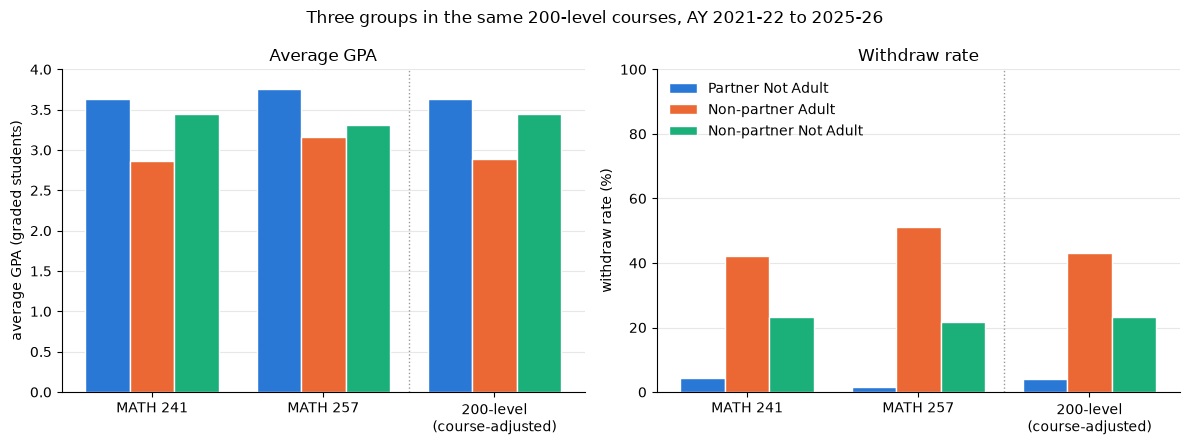

In [221]:
wd_200_df = df_wd[df_wd["course_level"] == "200-level"]
gpa_200_df = df_gpa[df_gpa["course_level"] == "200-level"]

# 200-level courses all three groups share (>= MIN_N students each)
counts_200 = wd_200_df.groupby(["course", "group"]).size().unstack("group").reindex(columns=GROUP_ORDER).fillna(0)
usable_200 = sorted(counts_200.index[(counts_200 >= MIN_N).all(axis=1)])

wd_200 = course_adjusted(wd_200_df.assign(withdrawn=wd_200_df["withdrawn"].astype(float)), "withdrawn", usable_200) * 100
gpa_200 = course_adjusted(gpa_200_df, "gpa", usable_200)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), facecolor="white")
bar_labels = [f"MATH {c}" for c in usable_200] + ["200-level\n(course-adjusted)"]
x = np.arange(len(bar_labels))
width = 0.26

for i, group in enumerate(GROUP_ORDER):
    offset = (i - 1) * width
    gpa_vals = [by_course.loc[(c, group), "avg_gpa"] for c in usable_200] + [gpa_200[group]]
    wd_vals = [by_course.loc[(c, group), "withdraw_rate"] for c in usable_200] + [wd_200[group]]
    ax1.bar(x + offset, gpa_vals, width, color=GROUP_COLORS[group], edgecolor="white", linewidth=1, label=group)
    ax2.bar(x + offset, wd_vals, width, color=GROUP_COLORS[group], edgecolor="white", linewidth=1, label=group)

ax1.set_ylim(0, 4.0)
ax1.set_ylabel("average GPA (graded students)")
ax1.set_title("Average GPA")
ax2.set_ylim(0, 100)
ax2.set_ylabel("withdraw rate (%)")
ax2.set_title("Withdraw rate")

for ax in (ax1, ax2):
    ax.set_facecolor("white")
    ax.set_xticks(x, bar_labels)
    ax.axvline(len(usable_200) - 0.5, color="#999999", linewidth=1, linestyle=":")  # single courses | summary
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)
ax2.legend(frameon=False, loc="upper left")

fig.suptitle(f"Three groups in the same 200-level courses, AY {full_years[0]} to {full_years[-1]}")
plt.tight_layout()
plt.show()

### 2.4 Final-grade distribution in MATH 241 and MATH 257

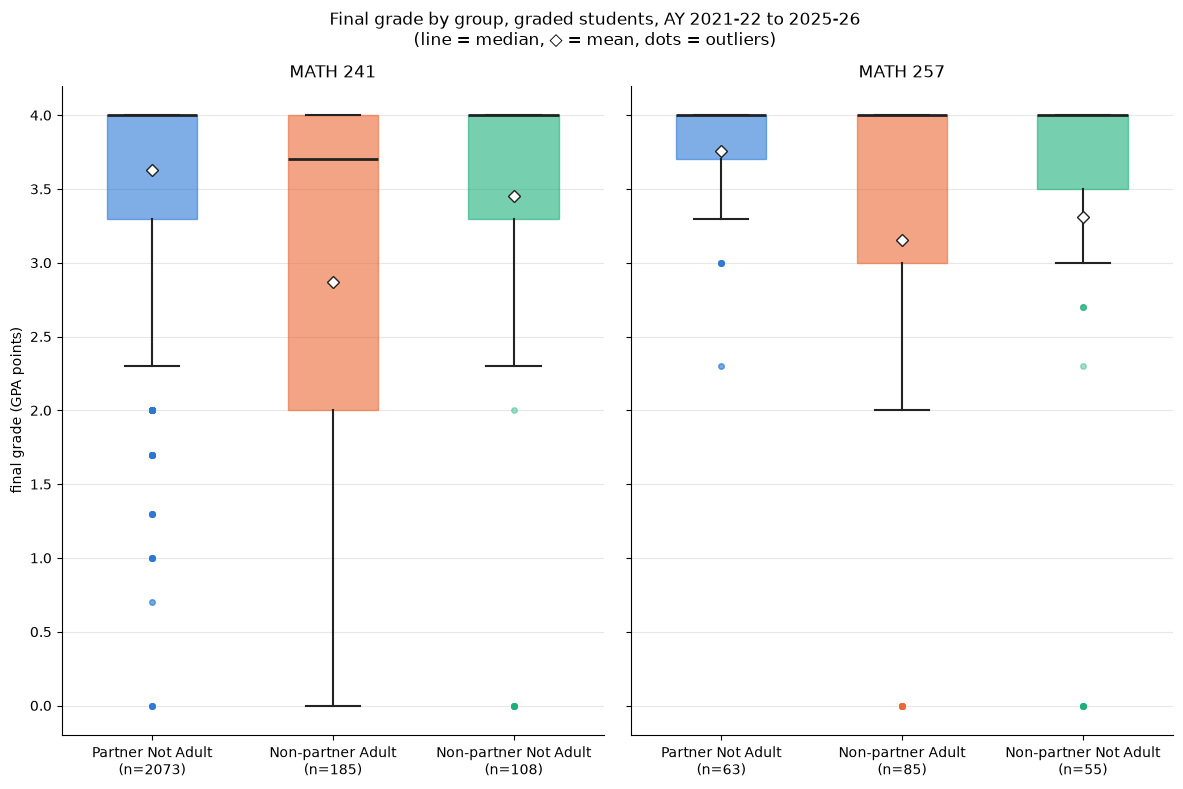

In [222]:
FOCUS_COURSES = [241, 257]

fig, axes = plt.subplots(1, len(FOCUS_COURSES), figsize=(12, 8), facecolor="white", sharey=True)

for ax, course in zip(axes, FOCUS_COURSES):
    data = [df_gpa.loc[(df_gpa["course"] == course) & (df_gpa["group"] == g), "gpa"] for g in GROUP_ORDER]

    bp = ax.boxplot(data, widths=0.5, patch_artist=True, showmeans=True,
                    medianprops=dict(color="#222222", linewidth=2),
                    meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor="#222222", markersize=6),
                    whiskerprops=dict(color="#222222", linewidth=1.5),
                    capprops=dict(color="#222222", linewidth=1.5),
                    capwidths=0.3,
                    flierprops=dict(marker="o", markersize=4, alpha=0.4))
    for box, flier, group in zip(bp["boxes"], bp["fliers"], GROUP_ORDER):
        box.set_facecolor(GROUP_COLORS[group])
        box.set_alpha(0.6)
        box.set_edgecolor(GROUP_COLORS[group])
        flier.set_markerfacecolor(GROUP_COLORS[group])
        flier.set_markeredgecolor(GROUP_COLORS[group])

    ax.set_xticks(range(1, len(GROUP_ORDER) + 1),
                  [f"{g}\n(n={len(d)})" for g, d in zip(GROUP_ORDER, data)])
    ax.set_title(f"MATH {course}")
    ax.set_facecolor("white")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)

axes[0].set_ylabel("final grade (GPA points)")
axes[0].set_ylim(-0.2, 4.2)
axes[0].set_yticks(np.arange(0, 4.01, 0.5))
fig.suptitle(f"Final grade by group, graded students, AY {full_years[0]} to {full_years[-1]}\n"
             "(line = median, ◇ = mean, dots = outliers)")
plt.tight_layout()
plt.show()

### 2.5 Non-partner Adult: final grade across courses

Only focus on the Non-partner Adult group, which is the only group spread across all course levels. Does the final grade go down as the course number goes up (harder courses)?

In [223]:
import math

GROUP = "Non-partner Adult"
np_adult = df_gpa[df_gpa["group"] == GROUP]

# average final grade per course
course_avg = (
    np_adult.groupby("course")["gpa"]
    .agg(n="count", avg_gpa="mean")
    .sort_index()  # course number, small -> large
)
dropped = course_avg[course_avg["n"] < MIN_N]
course_avg = course_avg[course_avg["n"] >= MIN_N]
print(f"courses shown: {len(course_avg)}  |  dropped (n < {MIN_N}): {dropped.index.tolist()}")

# position of each course on the x-axis: 0, 1, 2, ... in course-number order
course_avg["position"] = np.arange(len(course_avg))

# trend line = simple linear regression (ordinary least squares), one data point per graded student:
#   y = the student's GPA, x = the position of the student's course
students = np_adult[np_adult["course"].isin(course_avg.index)]
x_reg = students["course"].map(course_avg["position"]).to_numpy(dtype=float)
y_reg = students["gpa"].to_numpy(dtype=float)
slope, intercept = np.polyfit(x_reg, y_reg, 1)  # degree-1 least-squares fit = linear regression
course_avg["trend"] = intercept + slope * course_avg["position"]

# regression statistics
n_obs = len(y_reg)
residuals = y_reg - (intercept + slope * x_reg)
r_squared = 1 - (residuals ** 2).sum() / ((y_reg - y_reg.mean()) ** 2).sum()
se_slope = math.sqrt((residuals ** 2).sum() / (n_obs - 2) / ((x_reg - x_reg.mean()) ** 2).sum())
t_stat = slope / se_slope
p_value = math.erfc(abs(t_stat) / math.sqrt(2))  # two-sided; normal approximation is fine with ~2000 students

print(f"linear regression on {n_obs} students: GPA = {intercept:.3f} + {slope:.4f} x position")
print(f"  slope = {slope:+.4f} GPA per course step (SE {se_slope:.4f}, t = {t_stat:.2f}, p = {p_value:.2g})")
print(f"  R^2 = {r_squared:.3f}  ->  course position explains {r_squared * 100:.1f}% of the variation in grades")
print(f"  first -> last course: {slope * (len(course_avg) - 1):+.2f} GPA")

course_avg.round(2)

courses shown: 21  |  dropped (n < 15): [100, 200, 234, 292, 299, 314, 481]
linear regression on 1976 students: GPA = 2.509 + 0.0351 x position
  slope = +0.0351 GPA per course step (SE 0.0071, t = 4.93, p = 8e-07)
  R^2 = 0.012  ->  course position explains 1.2% of the variation in grades
  first -> last course: +0.70 GPA


,n,avg_gpa,position,trend
course,,,,
112,71,1.37,0,2.51
114,21,1.78,1,2.54
115,50,2.32,2,2.58
220,25,3.06,3,2.61
231,37,2.60,4,2.65
241,185,2.87,5,2.68
257,85,3.16,6,2.72
285,39,3.26,7,2.75
415,45,3.18,8,2.79


- x-axis: every course this group took, in course-number order, evenly spaced; each point = the course's average GPA. Courses with fewer than `MIN_N` graded students are left out.
- Dashed line: simple linear regression (ordinary least squares), `GPA = a + b x position`, where position = 0, 1, 2, ... is the course's place in that order. Each graded student is one data point, so big courses count more than small ones.

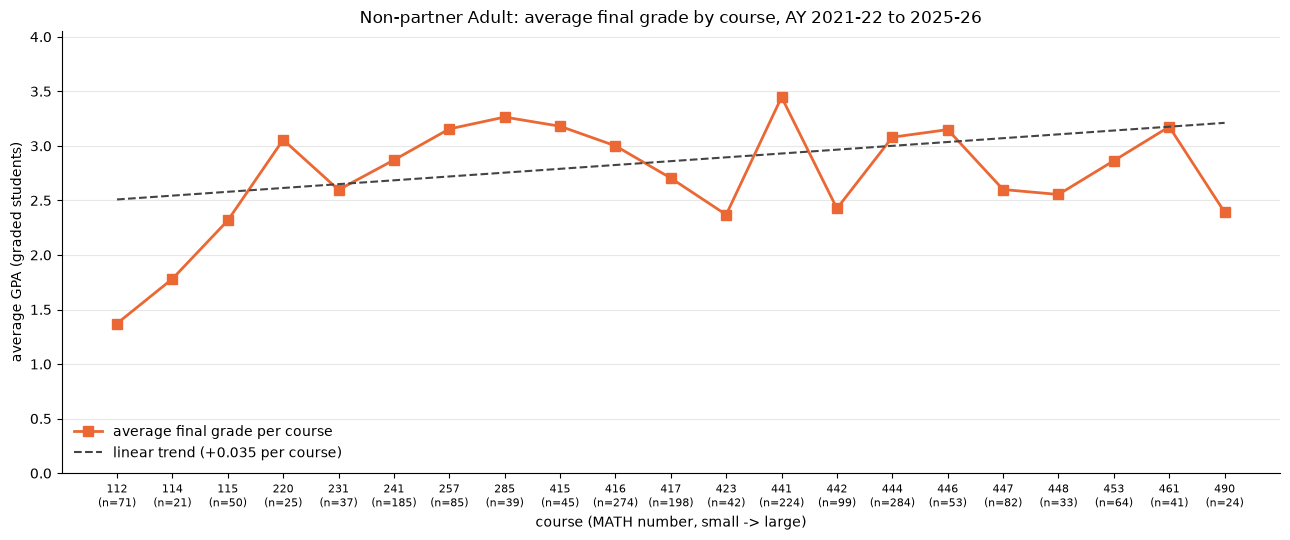

In [224]:
fig, ax = plt.subplots(figsize=(13, 5.5), facecolor="white")
ax.set_facecolor("white")
x = course_avg["position"].values

ax.plot(x, course_avg["avg_gpa"], color=GROUP_COLORS[GROUP], linewidth=2,
        marker=GROUP_MARKERS[GROUP], markersize=7, label="average final grade per course")
ax.plot(x, course_avg["trend"], color="#444444", linewidth=1.5, linestyle="--",
        label=f"linear trend ({slope:+.3f} per course)")

ax.set_xticks(x, [f"{c}\n(n={n})" for c, n in zip(course_avg.index, course_avg["n"])], fontsize=8)
ax.set_ylim(0, 4.05)
ax.set_xlabel("course (MATH number, small -> large)")
ax.set_ylabel("average GPA (graded students)")
ax.set_title(f"{GROUP}: average final grade by course, AY {full_years[0]} to {full_years[-1]}")
ax.legend(frameon=False, loc="lower left")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()